# alluvial capabilities: a tested tour

This notebook walks through **every public feature** of `alluvial`, the matplotlib port of the
[mapequation.org alluvial web app](https://www.mapequation.org/alluvial/). Each step has a short explanation, a
figure where one helps, and `assert` checks, so the notebook doubles as an executable specification: if a cell
fails, the behavior it describes has changed.

The sections:

1. [Inputs](#1-inputs): dicts, `partition` and DataFrames, `.tree`/`.ftree`/`.stree`/`.clu`, Infomap JSON, Infomap results and objects (state, memory and
   multilayer networks, `split_layers`), the web app's zip, `NetworkFile`
2. [Layout options](#2-layout-options): every `LayoutOptions` field
3. [Coloring](#3-coloring): the color modes, schemes, tones and offsets, highlight groups and legends
4. [Hierarchy](#4-hierarchy): `module_level`, `expand`, shadows and outlines
5. [Module names and order](#5-module-names-and-order)
6. [Drawing](#6-drawing): axes, fonts, labels, palettes, gradients, rasterizing, restyling, saving figures
7. [Geometry access](#7-geometry-access): the layout without matplotlib, `to_dict`
8. [Save and load](#8-save-and-load): `save_diagram`, `read`, the web app
9. [Error handling](#9-error-handling): typical mistakes and their messages
10. [Performance notes](#10-performance-notes)

The data are the small files bundled in the repository's `tests/data` plus a few seeded Infomap runs, so the whole
notebook runs in well under two minutes. The shorter, story-style introduction is `docs/tutorial.ipynb`.

In [1]:
import json
import os
import random
import shutil
import subprocess
import sys
import tempfile
import time
import warnings
import zipfile
from itertools import pairwise
from pathlib import Path

import infomap
import matplotlib as mpl
import matplotlib.pyplot as plt

import alluvial

plt.rcParams["figure.dpi"] = 90  # keeps the stored notebook small


def find_data() -> Path:
    "The repository's tests/data, found from the working directory (or $ALLUVIAL_DATA)."
    if "ALLUVIAL_DATA" in os.environ:
        return Path(os.environ["ALLUVIAL_DATA"])
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "tests" / "data" / "multilevel_t0.tree").exists():
            return base / "tests" / "data"
    raise FileNotFoundError("run the notebook inside the alluvial-py checkout, or set ALLUVIAL_DATA")


DATA = find_data()
OUT = Path(tempfile.mkdtemp(prefix="alluvial-capabilities-"))  # everything this notebook writes goes here


def same(a, b) -> bool:
    "Two geometries are identical: every coordinate, color index, label and option, bit for bit."
    return a.to_dict() == b.to_dict()


LABEL_KEYS = {
    "label",
    "largest_leaf_names",
    "name_candidates",
    "name_highlight_indices",
    "name_insignificant",
}


def close(a, b, tol=1e-9, labels=True) -> bool:
    "Like `same`, but coordinates and flows may differ by float rounding (at most `tol`); optionally skip node labels."

    def eq(x, y):
        if isinstance(x, float) and isinstance(y, float):
            return abs(x - y) <= tol
        if isinstance(x, dict) and isinstance(y, dict):
            keys = x.keys() if labels else x.keys() - LABEL_KEYS
            return x.keys() == y.keys() and all(eq(x[k], y[k]) for k in keys)
        if isinstance(x, list) and isinstance(y, list):
            return len(x) == len(y) and all(map(eq, x, y))
        return x == y

    return eq(a.to_dict(), b.to_dict())


assert sorted(alluvial.__all__) == sorted(
    [
        "SCHEMES",
        "AlluvialGeometry",
        "HighlightLabel",
        "LayoutOptions",
        "ModuleInfo",
        "NetworkFile",
        "NodeInfo",
        "__version__",
        "draw",
        "from_dataframe",
        "get_artists",
        "layout",
        "legend",
        "partition",
        "plot",
        "read",
        "save_diagram",
        "split_layers",
    ]
)

The public API is small. `layout` computes the diagram, `draw` renders it, and `plot` does both. `read` parses
one network, `partition` and `from_dataframe` make networks from plain data, and `save_diagram` writes a diagram
for the web app. The rest are data classes and a few small functions.

## 1. Inputs

### 1.1 Dicts, `partition()` and DataFrames

Any partition works, not only Infomap's: one from another community detection method, from metadata, or written
by hand.

- A plain dict `{node: module}` is one network. A node is an id or a name, and nodes are matched across networks
  by this key. A module is an int (a top module), a path string `"1:2"` (sub-module 2 of module 1) or a tuple
  `(1, 2)`. Module ids start at 1, as in Infomap.
- `alluvial.partition(modules, flows=None, name=None)` makes the same network as a `NetworkFile`. It adds flows
  (normalized to sum to 1) and a name.
- A pandas DataFrame in long format, with one row per network and node, goes straight to `layout` or `plot`. Its
  columns are `network`, `node`, `module` and, optionally, `flow`. `alluvial.from_dataframe(df, network=...,
  node=..., module=..., flow=...)` takes other column names and returns one `partition` per network.

Without flows, every node of a network gets the same flow, 1/N. When no input has flows, `module_size` and
`sort_modules_by` default to `"nodes"`, so the modules are sized and sorted by their node counts.

[[('1', 0.429), ('2', 0.286), ('3', 0.286)], [('2', 0.571), ('1', 0.286), ('3', 0.143)], [('2', 0.571), ('1', 0.429)]]
2021 2021 [('Ann', 1, '1:1', 0.385), ('Bo', 2, '1:2', 0.231), ('Cy', 3, '2:1', 0.077)]


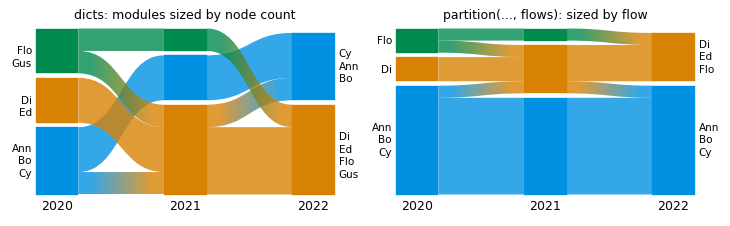

In [2]:
y2020 = {"Ann": 1, "Bo": 1, "Cy": 1, "Di": 2, "Ed": 2, "Flo": 3, "Gus": 3}
y2021 = {"Ann": 1, "Bo": 1, "Cy": 2, "Di": 2, "Ed": 2, "Flo": 2, "Gus": 3}
y2022 = {
    "Ann": "1",
    "Bo": "1",
    "Cy": (1,),
    "Di": 2,
    "Ed": 2,
    "Flo": 2,
    "Gus": 2,
}  # path strings and tuples work too
partitions = {"2020": y2020, "2021": y2021, "2022": y2022}

counted = alluvial.layout(partitions.values(), names=list(partitions))
print([[(m.id, round(m.flow, 3)) for m in n.modules] for n in counted.networks])
assert (counted.options.module_size, counted.options.sort_modules_by) == (
    "nodes",
    "nodes",
)  # no flows anywhere
assert [m.id for m in counted.networks[2].modules] == [
    "2",
    "1",
]  # sorted by node count, largest at the bottom

seniority = {"Ann": 5, "Bo": 3, "Cy": 1, "Di": 1, "Ed": 1, "Flo": 1, "Gus": 1}  # any non-negative weights
nf = alluvial.partition(y2021, seniority, name="2021")
print(nf.name, nf.id, [(n.name, n.id, n.path, round(n.flow, 3)) for n in nf.nodes[:3]])
assert nf.nodes[0].flow == 5 / 13 and abs(sum(n.flow for n in nf.nodes) - 1) < 1e-12  # normalized
weighted = alluvial.layout([alluvial.partition(m, seniority, name=y) for y, m in partitions.items()])
assert (weighted.options.module_size, weighted.options.sort_modules_by) == ("flow", "flow")

fig, axs = plt.subplots(1, 2, figsize=(8, 2.4), layout="constrained")
alluvial.draw(counted, axs[0])
axs[0].set_title("dicts: modules sized by node count", fontsize="medium")
alluvial.draw(weighted, axs[1])
axs[1].set_title("partition(..., flows): sized by flow", fontsize="medium");

The same networks as a DataFrame, with and without a flow column:

In [3]:
import pandas as pd

df = pd.DataFrame(
    [(year, node, module) for year, modules in partitions.items() for node, module in modules.items()],
    columns=["network", "node", "module"],
)
print(df.head(3).to_string(index=False))
as_partitions = [alluvial.partition(m, name=y) for y, m in partitions.items()]
assert same(alluvial.layout(df), alluvial.layout(as_partitions))  # one partition per network value

with_flow = df.assign(flow=df["node"].map(seniority))  # a column named "flow" is used as it is
assert same(alluvial.layout(with_flow), weighted)

renamed = with_flow.rename(columns={"network": "year", "node": "who", "module": "group", "flow": "weight"})
networks = alluvial.from_dataframe(renamed, network="year", node="who", module="group", flow="weight")
print([(nf.name, len(nf.nodes)) for nf in networks])
assert same(alluvial.layout(networks), weighted)

network node module
   2020  Ann      1
   2020   Bo      1
   2020   Cy      1
[('2020', 7), ('2021', 7), ('2022', 7)]


### 1.2 Infomap output files: `.tree`, `.ftree`, `.stree`, `.clu`

Infomap's text outputs are read by their suffix. `alluvial.read` returns a `NetworkFile`, which shows what was
read: the format, the nodes with their module paths and flows, and Infomap's header data. A `.tree` and an `.ftree`
of the same run hold the same partition (the `.ftree` adds the links), so they give the same diagram.

In [4]:
planted = {ext: [DATA / f"planted_t{i}.{ext}" for i in range(3)] for ext in ("tree", "ftree", "clu", "json")}
ML = [DATA / f"multilevel_t{i}.tree" for i in range(3)]  # three levels: modules, sub-modules, nodes

nf = alluvial.read(planted["tree"][0])
print(
    nf.format,
    nf.name,
    nf.id,
    len(nf.nodes),
    "nodes,",
    nf.num_top_modules,
    "top modules, codelength",
    nf.codelength,
)
node = nf.nodes[0]
print("first node:", node.name, node.path, node.flow, node.identifier)

assert nf.format == "tree" and nf.id == "planted_t0" and nf.name == "planted_t0.tree"
assert len(nf.nodes) == 110 and node.path == "1:1"
assert abs(sum(n.flow for n in nf.nodes) - 1) < 1e-6

assert same(
    alluvial.layout(planted["tree"]),
    alluvial.layout(planted["ftree"], names=[p.name for p in planted["tree"]]),
)

tree planted_t0.tree planted_t0 110 nodes, 4 top modules, codelength 5.48569
first node: v1 1:1 0.00704225 1


A `.clu` file holds one module per node (no hierarchy), and an `.stree` (state tree, from `-o states` or
Infomap's `--output stree`) can have insignificant levels, written with `;` in the path.

clu: clu 1 level(s); stree: stree 3 levels


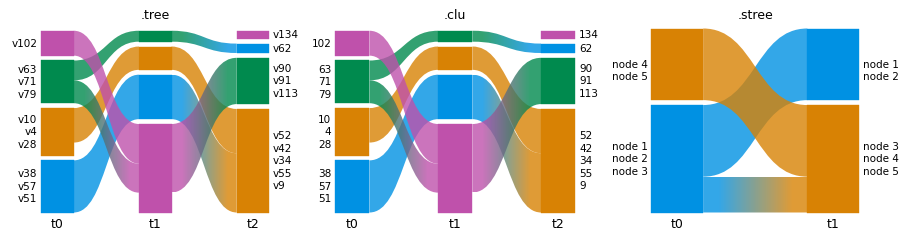

In [5]:
clu = alluvial.read(planted["clu"][0])
stree = alluvial.read(DATA / "debug5_0.stree")
print("clu:", clu.format, clu.num_levels, "level(s);", "stree:", stree.format, stree.num_levels, "levels")
assert clu.format == "clu" and clu.num_levels == 1
assert stree.format == "stree" and stree.num_levels == 3

fig, axs = plt.subplots(1, 3, figsize=(10, 2.6), layout="constrained")
for ax, (title, files) in zip(
    axs,
    [
        (".tree", planted["tree"]),
        (".clu", planted["clu"]),
        (".stree", [DATA / "debug5_0.stree", DATA / "debug5_1.stree"]),
    ],
):
    alluvial.plot(files, ax=ax, names=[f"t{i}" for i in range(len(files))])
    ax.set_title(title, fontsize="medium")

### 1.3 Infomap JSON

Infomap's `-o json` output works as a path or as the parsed `dict`. JSON keeps more of Infomap's data (the
arguments, the codelength savings, the `modules` list), all of it on the `NetworkFile`.

In [6]:
with open(planted["json"][0]) as f:
    as_dict = json.load(f)
from_path = alluvial.read(planted["json"][0])
from_dict = alluvial.read(as_dict, name="planted_t0.json", network_id="planted_t0")
print(
    from_path.format,
    from_path.version,
    from_path.args,
    len(from_path.raw_modules or []),
    "modules in the JSON",
)

assert from_path.format == "json" and from_dict.format == "json"
assert [n.path for n in from_path.nodes] == [n.path for n in from_dict.nodes]
assert same(alluvial.layout(planted["json"]), alluvial.layout([as_dict, *planted["json"][1:]], names=[p.name for p in planted["json"]], ids=[p.stem for p in planted["json"]]))  # fmt: skip

json v2.15.1  --silent --two-level --num-trials 10 5 modules in the JSON


### 1.4 Infomap results and objects

`infomap.run(network, seed=..., num_trials=...)` returns an immutable `Result`, which can be passed directly. An
`infomap.Network` gives the nodes names. Here are three snapshots of a planted-partition network: four groups of 12
nodes, where groups C and D merge in the last snapshot. All runs are seeded.

[4, 4, 3] top modules


<Axes: >

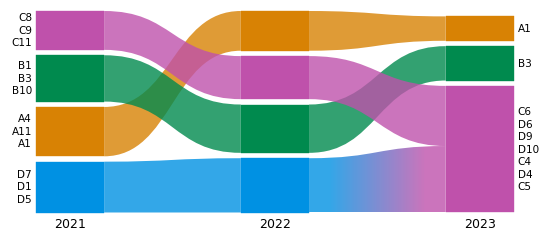

In [7]:
GROUPS = {"A": range(0, 12), "B": range(12, 24), "C": range(24, 36), "D": range(36, 48)}
NAMES = {u: f"{g}{u - r.start + 1}" for g, r in GROUPS.items() for u in r}


def snapshot(blocks, seed, p_in=0.5, p_out=0.01):
    "A random network with dense links inside each block of nodes."
    rng = random.Random(seed)
    block = {u: b for b, members in enumerate(blocks) for u in members}
    return [
        (u, v)
        for u in NAMES
        for v in NAMES
        if u < v and rng.random() < (p_in if block[u] == block[v] else p_out)
    ]


def find_modules(links):
    "One seeded Infomap run on the named nodes."
    network = infomap.Network().add_nodes(NAMES.items()).add_links(links)
    return infomap.run(network, seed=7, num_trials=5)


A, B, C, D = (list(r) for r in GROUPS.values())
runs = [
    find_modules(snapshot([A, B, C, D], seed=1)),
    find_modules(snapshot([A, B, C, D], seed=2)),
    find_modules(snapshot([A, B, C + D], seed=3)),
]
YEARS = ["2021", "2022", "2023"]
assert all(type(result).__name__ == "Result" for result in runs)
tops = [alluvial.read(result).num_top_modules for result in runs]
print(tops, "top modules")
assert tops == [4, 4, 3]

fig, ax = plt.subplots(figsize=(6, 2.6), layout="constrained")
alluvial.plot(runs, ax=ax, names=YEARS)

An `infomap.Infomap` object that has run works too: `alluvial` reads its latest result. It is the same partition
as `infomap.run` gives, so the diagram is identical.

In [8]:
im = infomap.Infomap(seed=7, num_trials=5)  # the stateful object API
im.add_nodes(NAMES.items())
im.add_links(snapshot([A, B, C, D], seed=1))
im.run()
assert alluvial.read(im).num_top_modules == 4
assert same(alluvial.layout([im, *runs[1:]]), alluvial.layout(runs))

### 1.5 State and memory networks

In a state (memory) network, a physical node can have several state nodes, and the state nodes can sit in
different modules: here the physical nodes `p6` to `p9` (later `p3` to `p6`) take part in both groups X and Y.
`read` takes the state level by default (`states=None` picks it for state and multilayer networks). Nodes are
matched across networks by `stateId ?? id`, and `colors="physical_id"` colors each physical node wherever its
states go.

20 state nodes of 16 physical nodes in 2 modules


Text(0.5, 1.0, 'colors="physical_id"')

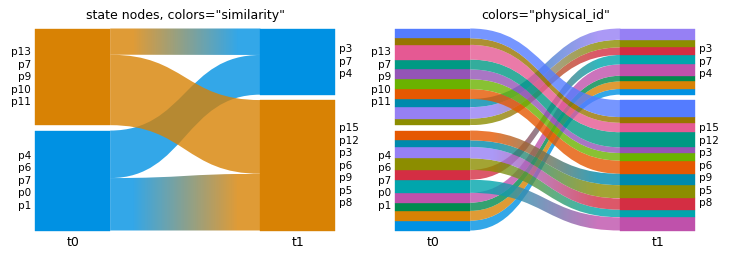

In [9]:
def memory_network(shared, seed):
    "16 physical nodes in two groups, X (p0-p7) and Y (p8-p15); the `shared` ones have a state node in each group."
    rng = random.Random(seed)
    network = infomap.Network().set_names({u: f"p{u}" for u in range(16)})
    groups, state = {"X": [], "Y": []}, 0
    for u in range(16):
        for side in ("X", "Y") if u in shared else ("X" if u < 8 else "Y",):
            network.add_state_node(state, u)
            groups[side].append(state)
            state += 1
    for members in groups.values():
        network.add_links((s, t) for s in members for t in members if s < t and rng.random() < 0.6)
    network.add_link(groups["X"][0], groups["Y"][0])
    return infomap.run(network, seed=7, num_trials=5)


mem = [memory_network(shared=range(6, 10), seed=1), memory_network(shared=range(3, 7), seed=2)]
states = alluvial.read(mem[0])
print(
    len(states.nodes),
    "state nodes of",
    len({n.id for n in states.nodes}),
    "physical nodes in",
    states.num_top_modules,
    "modules",
)
assert states.is_state_network and len(states.nodes) == 20
assert [alluvial.read(result).num_top_modules for result in mem] == [2, 2]

fig, axs = plt.subplots(1, 2, figsize=(8, 2.8), layout="constrained")
alluvial.plot(mem, ax=axs[0], names=["t0", "t1"], colors="similarity")
axs[0].set_title('state nodes, colors="similarity"', fontsize="medium")
alluvial.plot(mem, ax=axs[1], names=["t0", "t1"], colors="physical_id")
axs[1].set_title('colors="physical_id"', fontsize="medium")

`states=False` reads the physical level instead (Infomap's `write_tree(states=False)`): a physical node in two
modules then appears twice, with one identifier, and `read` warns that matching across networks uses the last one.

In [10]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    physical = alluvial.read(mem[0], states=False)
print(len(physical.nodes), "physical nodes;", "warning:", caught[0].message)
assert not physical.is_state_network and len(physical.nodes) == 20
assert "shared by several nodes" in str(caught[0].message)

20 physical nodes; warning: network 'network': 4 identifier(s) are shared by several nodes (e.g. '6', '7', '8'); cross-network matching uses the last node with each identifier


### 1.6 Multilayer networks and `split_layers`

A multilayer network is one Infomap run over all layers. `split_layers=True` (in `layout`, or `read(...,
split_layers=True)`, which returns one `NetworkFile` per layer) shows each layer as its own network, as the web
app's "split layers" does. Split layers match their nodes by physical id. `colors="layer"` colors the unsplit
network by layer.

[('network_layer1', 'Layer 1', 1), ('network_layer2', 'Layer 2', 2), ('network_layer3', 'Layer 3', 3)]


Text(0.5, 1.0, 'split_layers=True')

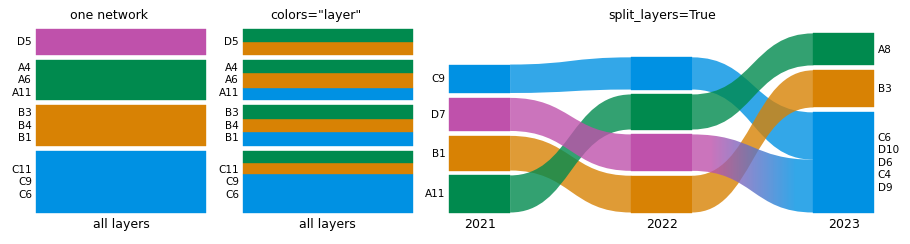

In [11]:
network = infomap.Network().set_names(NAMES)
for layer, blocks in enumerate([[A, B, C, D], [A, B, C, D], [A, B, C + D]], start=1):
    for u, v in snapshot(blocks, seed=layer):
        network.add_multilayer_intra_link(layer, u, v)
ml = infomap.run(network, seed=7, num_trials=5)

layers = alluvial.read(ml, split_layers=True)
print([(f.id, f.name, f.layer_id) for f in layers])
assert [f.layer_id for f in layers] == [1, 2, 3]
ids = [f"ml_layer{k}" for k in (1, 2, 3)]
assert same(
    alluvial.layout(layers, names=YEARS, ids=ids),
    alluvial.layout([ml], split_layers=True, names=YEARS, ids=ids),
)
assert len(alluvial.split_layers(alluvial.read(ml))) == 3  # the function behind split_layers=True

fig, axs = plt.subplots(1, 3, figsize=(10, 2.6), layout="constrained", width_ratios=[1, 1, 2.4])
alluvial.plot([ml], ax=axs[0], names=["all layers"])
axs[0].set_title("one network", fontsize="medium")
alluvial.plot([ml], ax=axs[1], names=["all layers"], colors="layer")
axs[1].set_title('colors="layer"', fontsize="medium")
alluvial.plot([ml], ax=axs[2], split_layers=True, names=YEARS)
axs[2].set_title("split_layers=True", fontsize="medium")

Layer names come from the JSON `layers` list when it has them (here two of four layers are named).

In [12]:
named = alluvial.read(DATA / "mlayer_named.json", split_layers=True)
print([f.name for f in named])
assert [f.name for f in named] == ["Alpha", "Layer 2", "Gamma", "Layer 4"]

['Alpha', 'Layer 2', 'Gamma', 'Layer 4']


### 1.7 The web app's zip, directories and lists of files

The web app accepts a `.zip` of network files, and so do `read` (which returns one `NetworkFile` per entry) and
`layout`. A directory or a list of paths also reads as a list.

In [13]:
zip_path = OUT / "planted.zip"
with zipfile.ZipFile(zip_path, "w") as z:
    for p in planted["ftree"]:
        z.write(p, p.name)

from_zip = alluvial.read(zip_path)
print([f.name for f in from_zip])
assert [f.name for f in from_zip] == [p.name for p in planted["ftree"]]
assert same(alluvial.layout([zip_path]), alluvial.layout(planted["ftree"]))
assert [f.name for f in alluvial.read(planted["ftree"])] == [f.name for f in from_zip]  # a list of paths

['planted_t0.ftree', 'planted_t1.ftree', 'planted_t2.ftree']


### 1.8 `NetworkFile`, names, ids and identifiers

Every input becomes a `NetworkFile`, and `layout` also accepts `NetworkFile`s, so you can read once and lay out
many times. `names=` and `ids=` set the network names (shown under the networks) and ids (used to address
networks in `expand`, `module_order` and `module_names`). `identifier="name"` matches nodes across networks by
name instead of id.

In [14]:
files = [alluvial.read(p) for p in planted["tree"]]
assert all(isinstance(f, alluvial.NetworkFile) for f in files)
geom = alluvial.layout(files, names=["first", "second", "third"], ids=["a", "b", "c"])
print([(n.id, n.name) for n in geom.networks])
assert [(n.id, n.name) for n in geom.networks] == [("a", "first"), ("b", "second"), ("c", "third")]

by_name = alluvial.layout(planted["tree"], identifier="name")
assert by_name.networks[0].modules[0].largest_leaf_names  # the labels are node names either way

[('a', 'first'), ('b', 'second'), ('c', 'third')]


### 1.9 Bipartite networks

Infomap marks the second node type of a bipartite network with `bipartiteStartId`. `show_bipartite_nodes=False`
hides those nodes, as the web app's "Show bipartite nodes" switch does.

In [15]:
bip = [DATA / "bipartite_t0.json", DATA / "bipartite_t1.json"]
shown = alluvial.layout(bip)
hidden = alluvial.layout(bip, show_bipartite_nodes=False)
flow = lambda g: sum(m.flow for m in g.networks[0].modules)  # noqa: E731
print(f"visible flow: {flow(shown):.3f} with, {flow(hidden):.3f} without the bipartite nodes")
assert alluvial.read(bip[0]).bipartite_start_id == 5
assert flow(hidden) < flow(shown)

visible flow: 1.000 with, 0.600 without the bipartite nodes


## 2. Layout options

`LayoutOptions` holds the web app's layout settings with its defaults; pass any field to `layout`/`plot` as a
keyword. `AlluvialGeometry.options` records what was used.

| option | default | effect |
|---|---|---|
| `height` | 600 | diagram height in layout px |
| `module_width` | 80 | width of the module columns |
| `streamline_fraction` | 2 | gap between networks, in module widths |
| `streamline_threshold` | 1 | thinner streamlines (px) are not drawn |
| `flow_threshold` | 0.005 | fraction of each network's flow hidden, smallest modules first |
| `margin_exponent` | 4 | margin between modules, `2 ** exponent` px |
| `zero_margins` | False | no margins at all |
| `vertical_align` | `"bottom"` | `"justify"` stretches margins so every network fills the height |
| `module_size` | `"flow"` | module height by `"flow"` or number of `"nodes"` |
| `sort_modules_by` | `"flow"` | module order: `"flow"`, `"nodes"`, `"node_id"`, `"highlight_index"` |

In [16]:
defaults = alluvial.LayoutOptions()
print(defaults)
assert alluvial.LayoutOptions.from_ts(defaults.to_ts()) == defaults  # the web app's camelCase names
print(defaults.to_ts())

g = alluvial.layout(runs)
assert g.options == defaults and g.height == 600
assert all(n.width == 80 for n in g.networks)
gap = g.networks[1].x - (g.networks[0].x + g.networks[0].width)
assert gap == 2 * 80  # streamline_fraction * module_width

g2 = alluvial.layout(runs, height=300, module_width=40, streamline_fraction=4)
assert g2.height == 300 and g2.networks[0].width == 40
assert g2.networks[1].x - (g2.networks[0].x + 40) == 4 * 40

LayoutOptions(height=600.0, module_width=80.0, streamline_fraction=2.0, streamline_threshold=1.0, flow_threshold=0.005, margin_exponent=4.0, zero_margins=False, vertical_align='bottom', module_size='flow', sort_modules_by='flow')
{'height': 600.0, 'moduleWidth': 80.0, 'streamlineFraction': 2.0, 'streamlineThreshold': 1.0, 'flowThreshold': 0.005, 'marginExponent': 4.0, 'zeroMargins': False, 'verticalAlign': 'bottom', 'moduleSize': 'flow', 'sortModulesBy': 'flow'}


Margins, alignment, module size and sort order, side by side:

largest margin in network 0: {'defaults': 16.0, 'margin_exponent=6': 40.0, 'zero_margins=True': 0.0, 'vertical_align="justify"': 16.0, 'module_size="nodes"': 16.0, 'sort_modules_by="nodes"': 16.0}


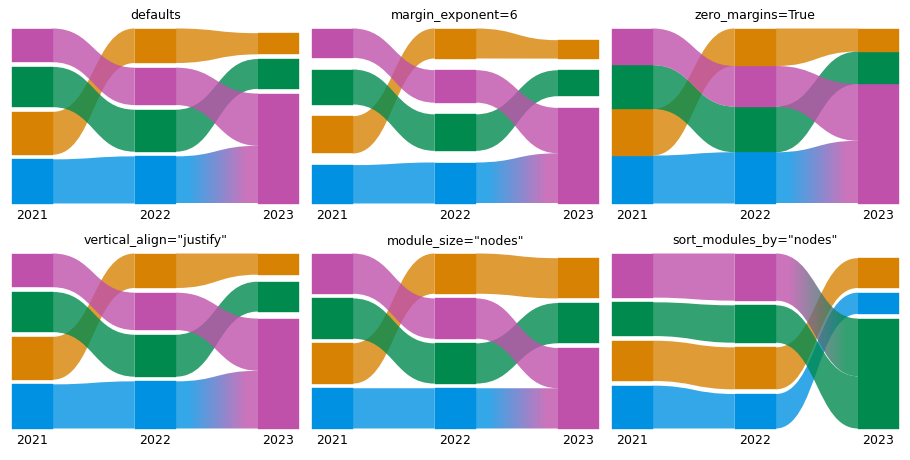

In [17]:
variants = {
    "defaults": {},
    "margin_exponent=6": {"margin_exponent": 6},
    "zero_margins=True": {"zero_margins": True},
    'vertical_align="justify"': {"vertical_align": "justify"},
    'module_size="nodes"': {"module_size": "nodes"},
    'sort_modules_by="nodes"': {"sort_modules_by": "nodes"},
}
geoms = {title: alluvial.layout(runs, names=YEARS, **kw) for title, kw in variants.items()}

fig, axs = plt.subplots(2, 3, figsize=(10, 5), layout="constrained")
for ax, (title, g) in zip(axs.flat, geoms.items()):
    alluvial.draw(g, ax, module_labels=False)
    ax.set_title(title, fontsize="medium")


def column_span(g, i):
    ms = g.networks[i].modules
    return max(m.y + m.height for m in ms) - min(m.y for m in ms)


def gaps(g, i):
    ms = sorted(g.networks[i].modules, key=lambda m: m.y)
    return [b.y - (a.y + a.height) for a, b in pairwise(ms)]


# zero margins: the modules of a network touch; justify: every network spans the full height
assert max(gaps(geoms["zero_margins=True"], 0)) < 1e-9
assert max(gaps(geoms["margin_exponent=6"], 0)) > max(gaps(geoms["defaults"], 0))
assert all(abs(column_span(geoms['vertical_align="justify"'], i) - 600) < 1e-9 for i in range(3))
print("largest margin in network 0:", {t: round(max(gaps(g, 0)), 1) for t, g in geoms.items()})
assert geoms['module_size="nodes"'].options.module_size == "nodes"

`flow_threshold` hides the smallest modules until the hidden flow would exceed that fraction of the network's
flow; `streamline_threshold` drops thin streamlines (in px). `sort_modules_by="node_id"` (the mean node id) and
`"highlight_index"` (the color) give stable, reproducible orders.

In [18]:
few = alluvial.layout(ML, module_level=2)
fewer = alluvial.layout(ML, module_level=2, flow_threshold=0.2)
count = lambda g: sum(len(n.modules) for n in g.networks)  # noqa: E731
print(count(few), "modules at flow_threshold=0.005,", count(fewer), "at 0.2")
assert count(fewer) < count(few)

thin = alluvial.layout(ML, module_level=2, streamline_threshold=0)
thick = alluvial.layout(ML, module_level=2, streamline_threshold=5)
print(len(thin.streamlines), "streamlines at streamline_threshold=0,", len(thick.streamlines), "at 5 px")
assert len(thick.streamlines) < len(thin.streamlines)
assert min(s.avg_height for s in thick.streamlines) > 5

for key in ("node_id", "highlight_index"):
    g = alluvial.layout(runs, sort_modules_by=key)
    assert g.options.sort_modules_by == key

34 modules at flow_threshold=0.005, 25 at 0.2
30 streamlines at streamline_threshold=0, 29 at 5 px


## 3. Coloring

### 3.1 Color modes

`colors=` runs one of the web app's coloring operations after the build:

- `"module_id"` (default): by module id, so the same id has the same color in every network,
- `"similarity"`: matching modules across networks share a color,
- `"nodes"`: every node by its module in one network, `color_network` (the first one by default),
- `"hierarchy"`: sub-modules get colors close to their parent's (section 3.3),
- `"layer"` and `"physical_id"`: multilayer and state networks (shown in section 1),
- `None`: no coloring (gray, unless the input carries colors).

Each module's color is an index into `geometry.palette` (`-1` is gray), in `ModuleGeometry.highlight_index`.

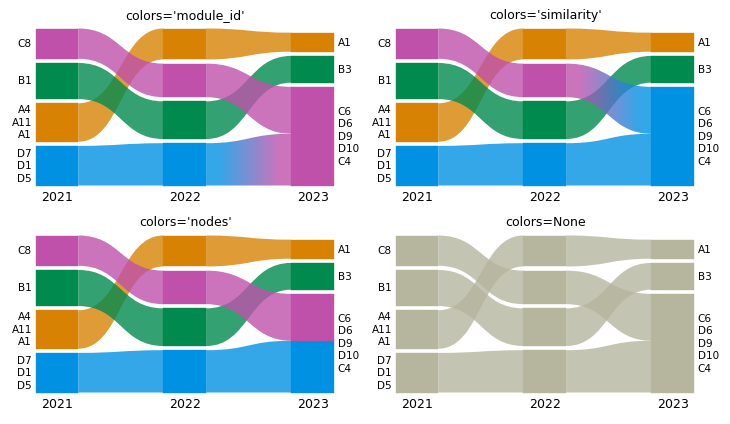

In [19]:
modes = ["module_id", "similarity", "nodes", None]
fig, axs = plt.subplots(2, 2, figsize=(8, 4.6), layout="constrained")
by_mode = {}
for ax, colors in zip(axs.flat, modes):
    by_mode[colors] = g = alluvial.layout(runs, names=YEARS, colors=colors)
    alluvial.draw(g, ax)
    ax.set_title(f"colors={colors!r}", fontsize="medium")
    used = {m.highlight_index for n in g.networks for m in n.modules}
    assert (used == {-1}) == (colors is None), colors
assert same(alluvial.layout(runs, names=YEARS), by_mode["module_id"])  # the default


def module_colors(g):
    "{(network index, module id): color} of the visible modules."
    return {(n.index, m.id): g.palette[m.highlight_index] for n in g.networks for m in n.modules}


by_id = module_colors(by_mode["module_id"])
assert all(by_id[i, m] == by_id[0, m] for i, m in by_id if (0, m) in by_id)  # one color per module id
assert by_id != module_colors(by_mode["similarity"])  # 2023 numbers its merged module C + D as module 1

`color_network` picks the network whose modules color the nodes, as selecting a network does in the web app: an
index, a network id, or a name given with `names=`. Coloring by the first network shows where each module goes;
coloring by the last shows where each module came from.

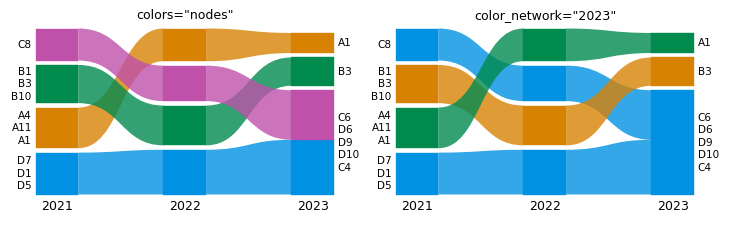

In [20]:
last = alluvial.layout(runs, names=YEARS, colors="nodes", color_network="2023")
assert same(last, alluvial.layout(runs, names=YEARS, colors="nodes", color_network=2))  # by index
assert same(last, alluvial.layout(runs, names=YEARS, colors="nodes", color_network="net2"))  # by network id
assert same(
    by_mode["nodes"], alluvial.layout(runs, names=YEARS, colors="nodes", color_network=0)
)  # the default
for g, k in ((by_mode["nodes"], 0), (last, 2)):  # every module of the color network has a color of its own
    indices = [{grp.highlight_index for grp in m.groups} for m in g.networks[k].modules]
    assert all(len(s) == 1 for s in indices) and len(set.union(*indices)) == len(indices)

fig, axs = plt.subplots(1, 2, figsize=(8, 2.4), layout="constrained")
for ax, (title, g) in zip(axs, [('colors="nodes"', by_mode["nodes"]), ('color_network="2023"', last)]):
    alluvial.draw(g, ax)
    ax.set_title(title, fontsize="medium")

### 3.2 Color schemes

`scheme=` picks one of the web app's 65 schemes, or takes your own list of colors. `alluvial.SCHEMES` is a tuple
of their names. Module colors are categories, so pick a categorical scheme: the C3 schemes, `"Tableau10"`,
`"Category10"`, `"Paired"`, `"Set2"` and the like. The sequential and diverging schemes in the list are there for
the web app's sake; their colors are hard to tell apart. `geometry.palette` holds the colors the coloring took
from the scheme.

65 schemes, e.g. ('Accent', 'Category10', 'Dark2', 'Paired', 'Pastel1', 'Pastel2')
4 colors used: ('#a6cee3', '#1f78b4', '#b2df8a', '#33a02c')


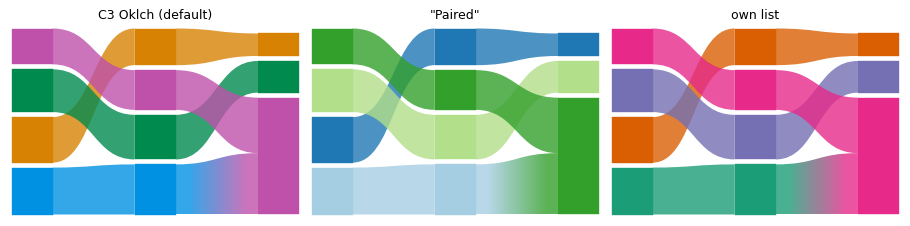

In [21]:
print(len(alluvial.SCHEMES), "schemes, e.g.", alluvial.SCHEMES[:6])
assert (
    isinstance(alluvial.SCHEMES, tuple) and len(alluvial.SCHEMES) == 65 and "C3 Sinebow" in alluvial.SCHEMES
)

paired = alluvial.layout(runs, scheme="Paired")
brewer = tuple(mpl.colors.to_hex(c) for c in mpl.colormaps["Paired"].colors)  # matplotlib has the same scheme
print(len(paired.palette), "colors used:", paired.palette)
assert paired.palette == brewer[: len(paired.palette)]  # the colors the coloring took from the scheme
mine = alluvial.layout(runs, scheme=["#1b9e77", "#d95f02", "#7570b3", "#e7298a"])
assert mine.palette[:4] == ("#1b9e77", "#d95f02", "#7570b3", "#e7298a")

fig, axs = plt.subplots(1, 3, figsize=(10, 2.4), layout="constrained")
for ax, (title, g) in zip(
    axs, [("C3 Oklch (default)", alluvial.layout(runs)), ('"Paired"', paired), ("own list", mine)]
):
    alluvial.draw(g, ax, module_labels=False, network_labels=False)
    ax.set_title(title, fontsize="medium")

### 3.3 Tones and offsets

The C3 schemes (`"C3 Oklch"`, the default, `"C3 Sinebow"`, `"C3 Turbo"`, `"C3 Rainbow"`, ...) are computed with
[c3](https://mapequation.github.io/c3), the color library of the web app. Two keywords change them:

- `tone=` sets the lightness and chroma. The tones are `"vivid"` (the default), `"bright"`, `"strong"`, `"deep"`,
  `"dark"`, `"soft"`, `"pastel"` and `"muted"`.
- `offset=` sets where the first color sits, in degrees around the hue source. On `"C3 Oklch"`, it is the hue of
  the first color (default 245, a blue). On the other C3 schemes, 360 is the whole scheme (default 0).

The other schemes are fixed lists of colors and ignore both.

To get the colors themselves, use c3 (the `c3-colors` package) directly: `c3.palette(n, tone=..., offset=...)`
gives the first `n` colors of `"C3 Oklch"`. Pass `tone="vivid"` for the default colors: c3's own default tone is
`"strong"`.

tones: ['vivid', 'bright', 'strong', 'deep', 'dark', 'soft', 'pastel', 'muted']


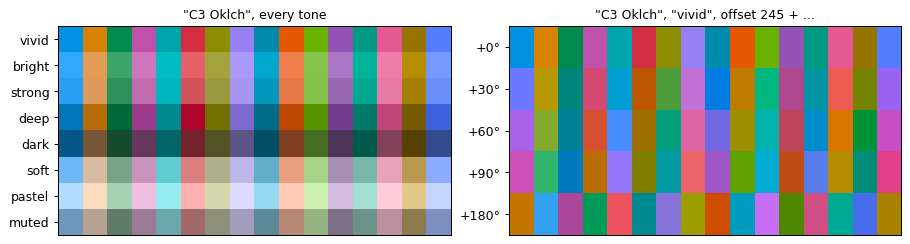

In [22]:
import c3
from matplotlib.colors import to_rgb

print("tones:", list(c3.tones))
assert len(c3.tones) == 8 and "vivid" in c3.tones
oklch = {tone: alluvial.layout(runs, scheme="C3 Oklch", tone=tone).palette for tone in c3.tones}
assert all(
    list(colors) == c3.palette(len(colors), tone=tone) for tone, colors in oklch.items()
)  # c3's colors
assert len({colors[0] for colors in oklch.values()}) == 8  # every tone gives other colors
default = alluvial.layout(runs).palette
assert default == oklch["vivid"] != oklch["strong"]  # "C3 Oklch" and "vivid" are the defaults
assert alluvial.layout(runs, scheme="C3 Oklch", offset=245).palette == default  # 245 is the default
turned = alluvial.layout(runs, scheme="C3 Oklch", offset=245 + 90).palette
assert turned != default and list(turned) == c3.palette(len(turned), tone="vivid", offset=245 + 90)
assert (
    alluvial.layout(runs, scheme="Paired", tone="pastel", offset=90).palette == paired.palette
)  # lists ignore both

fig, axs = plt.subplots(1, 2, figsize=(10, 2.6), layout="constrained")
tones = {tone: c3.palette(16, tone=tone) for tone in c3.tones}
offsets = {f"{o:+d}°": c3.palette(16, tone="vivid", offset=245 + o) for o in (0, 30, 60, 90, 180)}
panels = [('"C3 Oklch", every tone', tones), ('"C3 Oklch", "vivid", offset 245 + ...', offsets)]
for ax, (title, rows) in zip(axs, panels):
    ax.imshow([[to_rgb(c) for c in colors] for colors in rows.values()], aspect="auto")
    ax.set_yticks(range(len(rows)), list(rows))
    ax.set_xticks([])
    ax.set_title(title, fontsize="medium")

`colors="hierarchy"` colors the modules by their place in the module hierarchy, with c3's `hierarchy()`, as the
web app's coloring by module hierarchy does:

- sub-modules get colors close to their parent's,
- the same module path gets the same color in every network,
- with a C3 scheme, the top modules take its colors in the given tone and offset,
- with a list of colors, such as `"Tableau10"` or your own, the top modules take the colors of the list.

colors="hierarchy" 15 module paths, 15 colors
colors="hierarchy", "Tableau10" 15 module paths, 15 colors


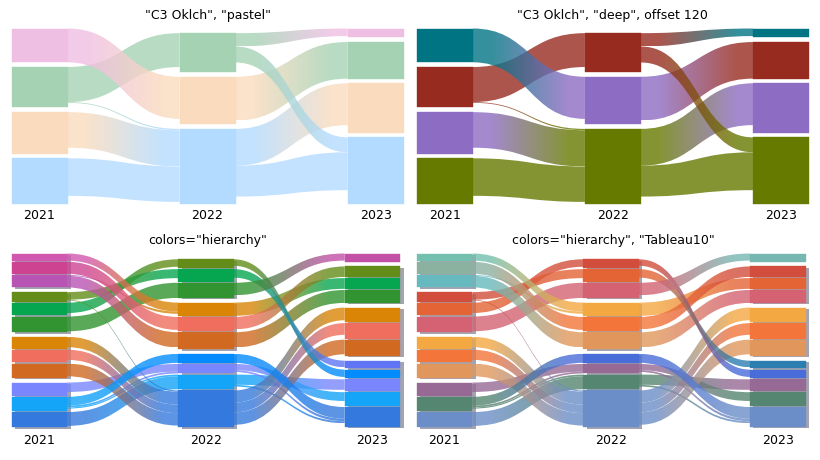

In [23]:
cases = {
    '"C3 Oklch", "pastel"': dict(scheme="C3 Oklch", tone="pastel"),
    '"C3 Oklch", "deep", offset 120': dict(scheme="C3 Oklch", tone="deep", offset=120),
    'colors="hierarchy"': dict(colors="hierarchy", module_level=2),
    'colors="hierarchy", "Tableau10"': dict(colors="hierarchy", module_level=2, scheme="Tableau10"),
}
fig, axs = plt.subplots(2, 2, figsize=(9, 5), layout="constrained")
geoms = {}
for ax, (title, kw) in zip(axs.flat, cases.items()):
    geoms[title] = g = alluvial.layout(ML, names=YEARS, **kw)
    alluvial.draw(g, ax, module_labels=False)
    ax.set_title(title, fontsize="medium")
assert geoms['"C3 Oklch", "pastel"'].palette[0] in oklch["pastel"]
assert geoms['colors="hierarchy", "Tableau10"'].palette != geoms['colors="hierarchy"'].palette
for title in ('colors="hierarchy"', 'colors="hierarchy", "Tableau10"'):
    g = geoms[title]
    by_path = {}
    for n in g.networks:
        for m in n.modules:
            assert m.highlight_index >= 0, (m.id, m.level, m.highlight_index)
            by_path.setdefault(m.path, set()).add(g.palette[m.highlight_index])
    assert all(len(c) == 1 for c in by_path.values())  # one color per module path in every network
    print(title, len(by_path), "module paths,", len(g.palette), "colors")

`save_diagram` stores the scheme, tone and offset (`colorScheme`, `colorTone`, `colorOffset` in the `alluvial`
block), and a reload restores them as the web app does: the saved colors come back, and coloring again uses the
saved tone and offset. A `tone` or `offset` you pass wins, and another `scheme` drops the saved offset.

In [24]:
kw = dict(names=YEARS, scheme="C3 Oklch", tone="soft", offset=12.5, colors="hierarchy", module_level=2)
original = alluvial.layout(ML, **kw)
saved = alluvial.save_diagram(ML, OUT / "toned.zip", **kw)
with zipfile.ZipFile(saved) as z:
    block = json.loads(z.read(z.namelist()[0]))["alluvial"]["diagram"]
print({k: block[k] for k in ("colorScheme", "colorTone", "colorOffset")})
assert (block["colorScheme"], block["colorTone"], block["colorOffset"]) == ("C3 Oklch", "soft", 12.5)
reloaded = alluvial.read(saved)
assert alluvial.layout(reloaded).palette == original.palette  # the saved colors
again = alluvial.layout(reloaded, colors="hierarchy")  # recolored with the restored scheme, tone and offset
assert again.palette == original.palette
pastel = alluvial.layout(reloaded, colors="hierarchy", tone="pastel")  # a tone you pass wins
assert pastel.palette != original.palette
other = alluvial.layout(
    reloaded, colors="hierarchy", scheme="C3 Turbo"
)  # another scheme drops the saved offset
assert (
    other.palette
    == alluvial.layout(ML, colors="hierarchy", module_level=2, scheme="C3 Turbo", tone="soft").palette
)
print("saved:", original.palette[:4], 'with tone="pastel":', pastel.palette[:4])

{'colorScheme': 'C3 Oklch', 'colorTone': 'soft', 'colorOffset': 12.5}
saved: ('#dc99b9', '#fc9a77', '#df7e78', '#7ed0e5') with tone="pastel": ('#f1c9dd', '#fbc6aa', '#f8b4b9', '#a3f0ff')


### 3.4 Highlight groups and legends

`highlight=` colors chosen nodes wherever they go and leaves the rest gray: either `{label: identifiers}`, or a
function of an `alluvial.NodeInfo` that returns a label (or `None`). `highlight_colors` sets the colors (a list
or `{label: color}`), and `legend=True` (or `alluvial.legend(ax, ...)`) adds a legend above the diagram.

(HighlightLabel(label='group A', highlight_index=0, color='tab:blue'), HighlightLabel(label='group C', highlight_index=1, color='tab:red'))


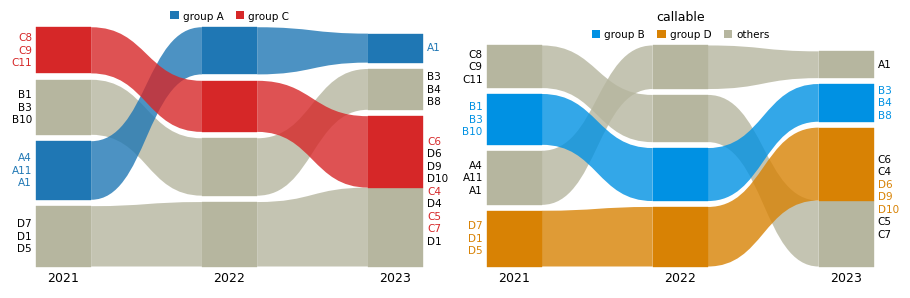

In [25]:
groups = {"group A": list(GROUPS["A"]), "group C": list(GROUPS["C"])}
g = alluvial.layout(
    runs, names=YEARS, highlight=groups, highlight_colors={"group A": "tab:blue", "group C": "tab:red"}
)
print(g.highlight_labels)
assert [h.label for h in g.highlight_labels] == ["group A", "group C"]
assert isinstance(g.highlight_labels[0], alluvial.HighlightLabel)


def by_group(node: alluvial.NodeInfo):
    return f"group {node.name[0]}" if node.name[0] in "BD" else None


g_fn = alluvial.layout(runs, names=YEARS, highlight=by_group)
assert [h.label for h in g_fn.highlight_labels] == ["group B", "group D"]

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
alluvial.draw(g, axs[0], legend=True)
alluvial.draw(g_fn, axs[1])
leg = alluvial.legend(axs[1], other="others", title="callable", frameon=False)
assert [t.get_text() for t in leg.get_texts()] == ["group B", "group D", "others"]
assert alluvial.get_artists(axs[1]).legend is leg

## 4. Hierarchy

Infomap finds hierarchies. `module_level=2` shows sub-modules down to level 2 (one value, or one per network);
`expand=[(network, module_id), ...]` opens single modules, in order. Expanded parents are drawn as gray
**shadows** (default) or solid dark gray **outlines** (`hierarchy="outline"`); `hierarchy=False` hides them.
`NetworkGeometry.outlines` holds the parent boxes and `ModuleGeometry.level` each module's level.

['1:1', '1:2', '1:3', '2', '3', '4']


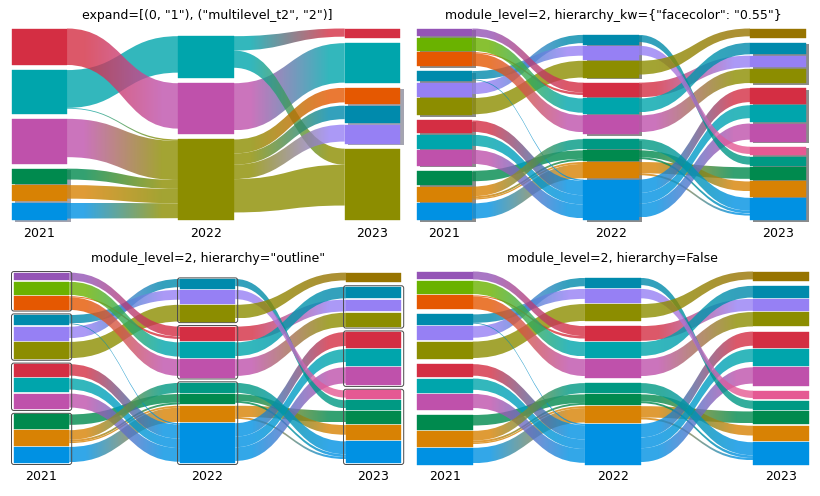

In [26]:
top = alluvial.layout(ML, names=YEARS)
lvl2 = alluvial.layout(ML, names=YEARS, module_level=2)
mixed = alluvial.layout(ML, names=YEARS, module_level=[2, 1, 2])
one = alluvial.layout(ML, names=YEARS, expand=[(0, "1"), ("multilevel_t2", "2")])

assert {m.level for n in top.networks for m in n.modules} == {1}
deepest = lambda g: [max(m.level for m in n.modules) for n in g.networks]  # noqa: E731
assert deepest(lvl2) == [2, 2, 2] and deepest(mixed) == [2, 1, 2]
assert [m.id for m in lvl2.networks[2].modules if m.level == 1] == ["4"]  # module 4 has no sub-modules
assert [o.path for o in one.networks[0].outlines] == ["1"] and [o.path for o in one.networks[2].outlines] == [
    "2"
]
print([m.id for m in one.networks[0].modules])

fig, axs = plt.subplots(2, 2, figsize=(9, 5.4), layout="constrained")
panels = [
    ('expand=[(0, "1"), ("multilevel_t2", "2")]', one, {}),
    ('module_level=2, hierarchy_kw={"facecolor": "0.55"}', lvl2, {"hierarchy_kw": {"facecolor": "0.55"}}),
    ('module_level=2, hierarchy="outline"', lvl2, {"hierarchy": "outline"}),
    ("module_level=2, hierarchy=False", lvl2, {"hierarchy": False}),
]
for ax, (title, geometry, kw) in zip(axs.flat, panels):
    alluvial.draw(geometry, ax, module_labels=False, **kw)
    ax.set_title(title, fontsize="medium")
    expected = 0 if kw.get("hierarchy") is False else sum(len(n.outlines) for n in geometry.networks)
    assert len(alluvial.get_artists(ax).outlines) == expected

## 5. Module names and order

`module_names` replaces a module's label (by default its largest nodes' names), either as
`{(network, module_id): name}` or as a function of an `alluvial.ModuleInfo`. `module_order` puts modules at given
positions, bottom to top; `...` stands for the unlisted modules. Networks are addressed by index, id, or a name
given with `names=`.

{'2021': ['4', '1', '2', '3'], '2022': ['4', '2', '3', '1'], '2023': ['3', '2', '1']}
[('1', 'A team'), ('4', 'D team'), ('2', 'B team'), ('3', 'C team')]


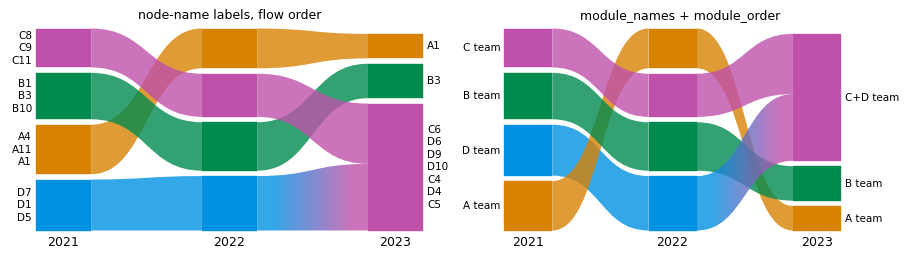

In [27]:
g = alluvial.layout(runs, names=YEARS)
print({n.name: [m.id for m in n.modules] for n in g.networks})


def name_by_groups(module: alluvial.ModuleInfo):
    "Name a module after the groups that hold at least a quarter of its nodes."
    letters = [name[0] for name in module.node_names]
    major = sorted({x for x in letters if letters.count(x) >= len(letters) / 4})
    return "+".join(major) + " team" if major else None


named = alluvial.layout(
    runs,
    names=YEARS,
    module_names=name_by_groups,
    module_order={"2021": ["1", ...], 2: ["1", ..., "3"]},
)
first, last = named.networks[0], named.networks[2]
print([(m.id, m.name) for m in first.modules])
lowest = lambda net: max(net.modules, key=lambda m: m.y).id  # noqa: E731  (y grows downwards)
highest = lambda net: min(net.modules, key=lambda m: m.y).id  # noqa: E731
assert lowest(first) == "1" and lowest(last) == "1" and highest(last) == "3"
assert sorted(m.name for m in last.modules) == ["A team", "B team", "C+D team"]

fig, axs = plt.subplots(1, 2, figsize=(10, 2.8), layout="constrained")
alluvial.draw(g, axs[0])
axs[0].set_title("node-name labels, flow order", fontsize="medium")
alluvial.draw(named, axs[1])
axs[1].set_title("module_names + module_order", fontsize="medium")
fig.canvas.draw()
drawn = {t.get_text() for t in alluvial.get_artists(axs[1]).module_labels if t.get_visible()}
assert {"A team", "C+D team"} <= drawn  # a name replaces the node-name label

A dict works the same way and wins for the modules it names: `module_names={("2021", "1"): "Core"}`. Names are
drawn on the first and last network only, as in the web app; the middle ones are kept in `ModuleGeometry.name`.

In [28]:
g = alluvial.layout(runs, names=YEARS, module_names={("2021", "1"): "Core", (1, "1"): "Middle"})
assert next(m for m in g.networks[0].modules if m.id == "1").name == "Core"
assert next(m for m in g.networks[1].modules if m.id == "1").name == "Middle"

## 6. Drawing

### 6.1 Axes, fonts and figure sizes

`draw(geometry, ax)` fills any axes, also in a grid with `layout="constrained"`. Every text size follows
`rcParams["font.size"]` (module labels `"small"`, network names `"medium"`) and the family follows `font.family`, so a paper's font settings apply
as they are. Without `ax=`, `plot`/`draw` make a figure sized by its content: taller with more modules (2 to 6 in), wider
with more networks and longer labels.

3 networks, 4 modules: 3.4 x 2.1 in
2 networks, 2 modules: 2.3 x 2.0 in


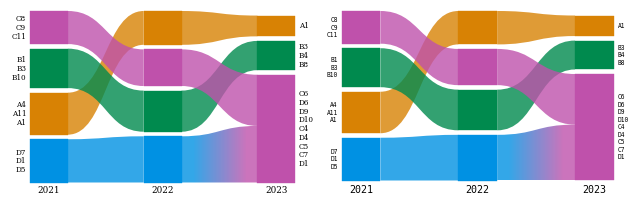

In [29]:
with plt.rc_context({"font.family": "serif", "font.size": 7}):
    fig, (left, right) = plt.subplots(1, 2, figsize=(7, 2.2), layout="constrained")
    alluvial.plot(runs, ax=left, names=YEARS)
    alluvial.plot(
        runs, ax=right, names=YEARS, fontsize=5, network_fontsize=8, text_kw={"family": "monospace"}
    )
art = alluvial.get_artists(left)
small = mpl.font_manager.font_scalings["small"]  # 0.833
assert art.network_labels[0].get_fontsize() == 7 and art.module_labels[0].get_fontsize() == 7 * small
assert art.module_labels[0].get_family() == ["serif"]
assert alluvial.get_artists(right).network_labels[0].get_fontsize() == 8

sizes = {}
for what, networks in {
    "3 networks, 4 modules": runs,
    "2 networks, 2 modules": [{"a": 1, "b": 2}] * 2,
}.items():
    ax = alluvial.plot(networks)  # its own figure
    sizes[what] = w, h = ax.figure.get_size_inches()
    print(f"{what}: {w:.1f} x {h:.1f} in")
    plt.close(ax.figure)
assert all(2 <= h <= 6 for w, h in sizes.values())
assert sizes["3 networks, 4 modules"][0] > sizes["2 networks, 2 modules"][0]  # wider with more networks

### 6.2 Label options

`module_labels`/`network_labels` switch labels off, `max_label_lines` caps the names per module,
`max_label_width` truncates long lines (points, `"auto"` or `None`), `avoid_label_overlap=False` reproduces the
web app's overlapping labels, `label_pad` sets the gap, `label_colors` colors names by their group, and
`label_kw`/`network_label_kw` style each kind of text.

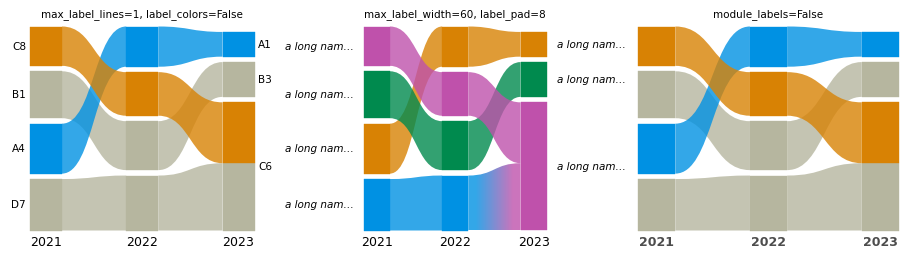

In [30]:
g = alluvial.layout(runs, names=YEARS, highlight=groups)
fig, axs = plt.subplots(1, 3, figsize=(10, 2.8), layout="constrained", width_ratios=[1, 1.3, 1])
alluvial.draw(g, axs[0], max_label_lines=1, label_colors=False)
axs[0].set_title("max_label_lines=1, label_colors=False", fontsize="small")
long = alluvial.layout(runs, names=YEARS, module_names=lambda m: f"a long name for module {m.id}")
alluvial.draw(
    long, axs[1], max_label_width=60, label_pad=8, avoid_label_overlap=False, label_kw={"style": "italic"}
)
axs[1].set_title("max_label_width=60, label_pad=8", fontsize="small")
alluvial.draw(g, axs[2], module_labels=False, network_label_kw={"weight": "bold", "color": "0.3"})
axs[2].set_title("module_labels=False", fontsize="small")

fig.canvas.draw()  # labels are fitted at draw time
visible = lambda ax: [t for t in alluvial.get_artists(ax).module_labels if t.get_visible()]  # noqa: E731
assert all("\n" not in t.get_text() for t in visible(axs[0]))
assert any(t.get_text().endswith("…") for t in visible(axs[1]))
assert alluvial.get_artists(axs[2]).module_labels == []
assert alluvial.get_artists(axs[2]).network_labels[0].get_fontweight() == "bold"

### 6.3 Palettes, colormaps, gradients and styles

`palette=` recolors at draw time: a list, a matplotlib colormap name or a `Colormap` (qualitative maps are used
as they are, continuous ones are sampled). `default_color` sets the gray. Streamlines between differently
colored modules get a horizontal gradient (`gradient=False` uses the left color). `streamline_alpha`,
`edgecolor`/`linewidth`, `module_kw`, `streamline_kw` and `hierarchy_kw` style the shapes.

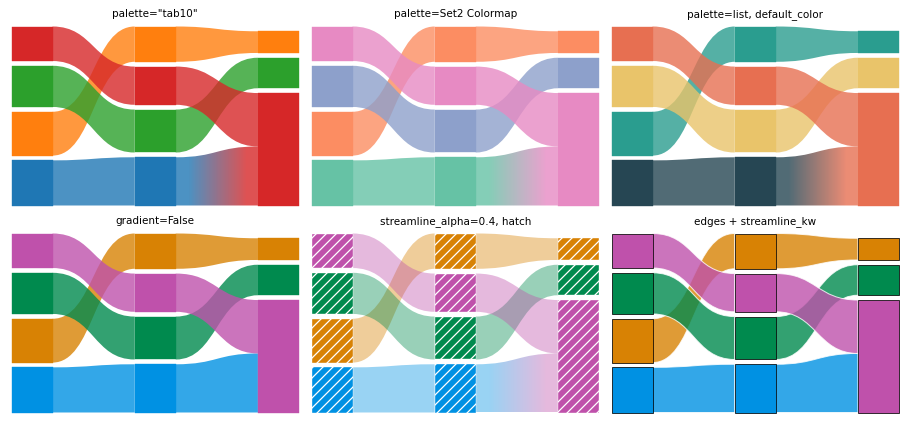

In [31]:
g = alluvial.layout(runs, names=YEARS, colors="module_id")
fig, axs = plt.subplots(2, 3, figsize=(10, 4.6), layout="constrained")
styles = {
    'palette="tab10"': dict(palette="tab10"),
    "palette=Set2 Colormap": dict(palette=mpl.colormaps["Set2"]),
    "palette=list, default_color": dict(
        palette=["#264653", "#2a9d8f", "#e9c46a", "#e76f51"], default_color="0.8"
    ),
    "gradient=False": dict(gradient=False),
    "streamline_alpha=0.4, hatch": dict(
        streamline_alpha=0.4, module_kw={"hatch": "///", "edgecolor": "white"}
    ),
    "edges + streamline_kw": dict(
        edgecolor="black",
        linewidth=0.6,
        streamline_kw={"edgecolor": "white", "linewidth": 0.8},
        gradient=False,
    ),
}
for ax, (title, kw) in zip(axs.flat, styles.items()):
    alluvial.draw(g, ax, module_labels=False, network_labels=False, **kw)
    ax.set_title(title, fontsize="small")

tab10 = mpl.colormaps["tab10"].colors
first = alluvial.get_artists(axs[0, 0]).modules[0]
assert tuple(first.get_facecolor()[:3]) == tuple(tab10[g.networks[0].modules[0].highlight_index])
images = [a for a in alluvial.get_artists(axs[0, 0]).streamlines if isinstance(a, mpl.image.AxesImage)]
assert images and not [
    a for a in alluvial.get_artists(axs[1, 0]).streamlines if isinstance(a, mpl.image.AxesImage)
]

### 6.4 Restyling with `get_artists`

`get_artists(ax)` returns the drawn artists (`modules`, `streamlines`, `module_labels`, `network_labels`,
`outlines`, `legend`) for changes after the fact. Each artist carries a `gid` like `module:<network>:<module>:<group>`,
which SVG output keeps as the element id.

11 module groups, 8 streamlines; e.g. module:net0:4:0


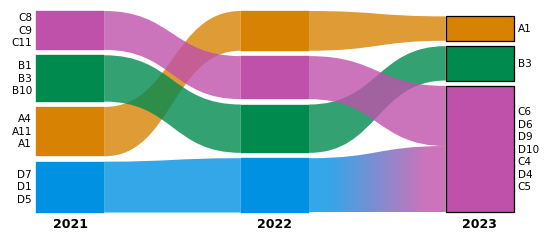

In [32]:
fig, ax = plt.subplots(figsize=(6, 2.6), layout="constrained")
alluvial.plot(runs, ax=ax, names=YEARS, module_level=1)
art = alluvial.get_artists(ax)
for text in art.network_labels:
    text.set_fontweight("bold")
for patch in art.modules:
    if patch.get_gid().startswith("module:net2:"):  # the last network
        patch.set_edgecolor("black")
        patch.set_linewidth(1)
print(len(art.modules), "module groups,", len(art.streamlines), "streamlines; e.g.", art.modules[0].get_gid())
assert art.geometry.networks[0].id == "net0" and art.modules[0].get_gid().startswith("module:net0:")
assert all(a.get_gid().startswith("streamline:") for a in art.streamlines)

### 6.5 Saving figures: PNG, PDF, SVG and `rasterized`

Figures save like any matplotlib figure, and stay vector in PDF and SVG (gradients are small images clipped to
the streamline). For very large diagrams, `rasterized=True` rasterizes the shapes and keeps the text as vector.

In [33]:
fig, ax = plt.subplots(figsize=(5, 2.4), layout="constrained")
alluvial.plot(runs, ax=ax, names=YEARS)
for ext in ("png", "pdf", "svg"):
    fig.savefig(OUT / f"figure.{ext}")
plt.close(fig)
svg = (OUT / "figure.svg").read_text()
assert 'id="network-label:net0"' in svg and 'id="streamline:' in svg
assert (OUT / "figure.pdf").read_bytes().startswith(b"%PDF") and (OUT / "figure.png").stat().st_size > 10_000

fig, ax = plt.subplots(figsize=(5, 2.4), layout="constrained")
alluvial.plot(runs, ax=ax, names=YEARS, rasterized=True, gradient=False)
fig.savefig(OUT / "raster.svg", dpi=150)
plt.close(fig)
raster = (OUT / "raster.svg").read_text()
assert "<image" in raster and "network-label:net0" in raster  # shapes as an image, text as vector
print({p.name: p.stat().st_size for p in sorted(OUT.glob("*.*")) if p.suffix in (".png", ".pdf", ".svg")})

{'figure.pdf': 9784, 'figure.png': 16035, 'figure.svg': 20289, 'raster.svg': 36388}


## 7. Geometry access

`layout` returns an `AlluvialGeometry` of frozen dataclasses in the web app's SVG coordinates (y grows
downwards): networks with their modules (each with color groups and a label), streamlines and the hierarchy
outlines. It needs no matplotlib, so it also feeds other renderers. `to_dict()` gives plain JSON-ready data, and
`AlluvialGeometry.from_dict` reads it back.

In [34]:
code = (
    "import sys, alluvial; g = alluvial.layout([sys.argv[1]]);"
    "print(len(g.networks[0].modules), 'matplotlib' in sys.modules)"
)
out = subprocess.run(
    [sys.executable, "-c", code, str(ML[0])], capture_output=True, text=True, check=True
).stdout
print("layout in a fresh process -> modules, matplotlib imported:", out.strip())
assert out.split() == ["4", "False"]

g = alluvial.layout(ML, names=YEARS, module_level=2)
data = g.to_dict()
text = json.dumps(data)
assert alluvial.AlluvialGeometry.from_dict(json.loads(text)) == g
print(sorted(data), f"{len(text) / 1000:.0f} kB of JSON")

m = g.networks[0].modules[0]
s = g.streamlines[0]
print(
    m.id,
    m.level,
    round(m.flow, 3),
    [round(v, 1) for v in (m.x, m.y, m.width, m.height)],
    m.largest_leaf_names[:3],
)
print(s.id, s.left, s.right, s.svg_path()[:60], "...")
assert abs(sum(grp.height for grp in m.groups) - m.height) < 1e-9
assert s.path()[0][1][0] == g.networks[s.left[0]].x + g.networks[s.left[0]].width

layout in a fresh process -> modules, matplotlib imported: 4 False
['height', 'highlight_labels', 'networks', 'options', 'palette', 'streamlines', 'width'] 39 kB of JSON
1:1 2 0.1 [0.0, 548.2, 80.0, 51.8] ('m50', 'm47', 'm49')
multilevel_t0_module1:1_group0_right--multilevel_t1_module1:2_group1_left (0, '1:1', 0) (1, '1:2', 1) M80,596.0122694042943C160,596.0122694042943,160,469.44373890 ...


The coordinates are enough for a renderer of your own. Here are the modules as plain matplotlib bars:

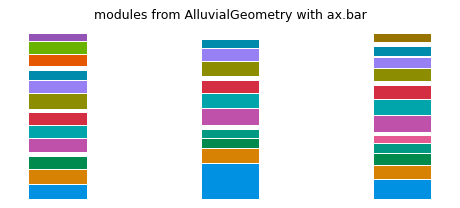

In [35]:
def css_rgb(color):
    "A palette entry is a CSS color, '#rrggbb' or 'rgb(r, g, b)'; matplotlib reads only the first."
    if color.startswith("rgb("):
        return tuple(int(v) / 255 for v in color[4:-1].split(","))
    return color


fig, ax = plt.subplots(figsize=(5, 2.2), layout="constrained")
for net in g.networks:
    for mod in net.modules:
        color = css_rgb(g.palette[mod.highlight_index]) if mod.highlight_index >= 0 else "0.7"
        ax.bar(
            mod.x,
            mod.height,
            width=mod.width,
            bottom=g.height - mod.y - mod.height,
            align="edge",
            color=color,
        )
ax.set_title("modules from AlluvialGeometry with ax.bar", fontsize="medium")
ax.set_axis_off()

## 8. Save and load

`save_diagram(networks, path, **layout_kwargs)` lays out the networks like `layout` and saves the diagram in the
web app's "Download diagram" format: "alluvial network files" (formatVersion 1), one Infomap-JSON file per network
with the colors, expanded modules, module names, custom module orders, the layout options and the color scheme
in an `alluvial` block. It writes a zip by default, a directory of loose files with `loose=True`, or one `.json`
for a one-network diagram. `read` loads them back in saved order and `layout` restores the same diagram: the same
modules, order, colors, names, options and network names. Three details differ: the coordinates agree up to float
rounding (the reload sums the module flows in another order, about 1e-13 px); for the same reason, node-name labels
can list nodes of exactly equal flow in another order; and the network ids are the saved file names unless `ids=`
sets them. Saving a reloaded diagram again reproduces it bit for bit.

In [36]:
kwargs = dict(
    names=YEARS,
    module_level=[1, 2, 2],
    scheme="Tableau10",
    module_names={("2021", "1"): "Core"},
    module_order={"2021": ["2", ...]},
    margin_exponent=5,
    module_width=60,
)
original = alluvial.layout(ML, **kwargs)
zip_saved = alluvial.save_diagram(ML, OUT / "diagram.zip", **kwargs)
dir_saved = alluvial.save_diagram(ML, OUT / "diagram", loose=True, **kwargs)
print(zip_saved.name, zipfile.ZipFile(zip_saved).namelist())
print(dir_saved.name, sorted(p.name for p in dir_saved.iterdir()))

reloaded = alluvial.read(zip_saved)
ids = [n.id for n in original.networks]
print([f.id for f in reloaded], "->", ids)
assert [f.name for f in reloaded] == YEARS
restored = alluvial.layout(reloaded, ids=ids)
assert close(restored, original, labels=False)  # everything restored, up to float rounding
assert [[(m.id, m.name, m.highlight_index) for m in n.modules] for n in restored.networks] == [
    [(m.id, m.name, m.highlight_index) for m in n.modules] for n in original.networks
]
assert restored.options == original.options and restored.palette == original.palette
assert same(alluvial.layout([zip_saved]), alluvial.layout([dir_saved]))  # zip and loose files agree
shuffled = sorted(dir_saved.iterdir(), reverse=True)
assert [f.name for f in alluvial.read(shuffled)] == YEARS  # read sorts the files of one save into saved order
assert same(alluvial.layout(alluvial.read(shuffled)), alluvial.layout([dir_saved]))

again = alluvial.save_diagram(reloaded, OUT / "again.zip")  # a reloaded diagram saves and reloads unchanged
assert same(alluvial.layout([again]), alluvial.layout([zip_saved]))

block = reloaded[0].alluvial
print(
    {k: block[k] for k in ("format", "formatVersion", "generator")},
    "options:",
    list(block["diagram"]["options"])[:5],
)
assert block["format"] == "alluvial-network" and block["formatVersion"] == 1
assert block["generator"] == f"alluvial (Python) {alluvial.__version__}"

diagram.zip ['00_2021.json', '01_2022.json', '02_2023.json']
diagram ['00_2021.json', '01_2022.json', '02_2023.json']
['00_2021', '01_2022', '02_2023'] -> ['multilevel_t0', 'multilevel_t1', 'multilevel_t2']


{'format': 'alluvial-network', 'formatVersion': 1, 'generator': 'alluvial (Python) 0.7.0'} options: ['height', 'marginExponent', 'zeroMargins', 'moduleWidth', 'streamlineFraction']


Keywords given to `layout` win over the stored values, and `restore_state=False` loads the files as plain Infomap
JSON (keeping their colors and expanded modules, but not the options, order and names). A single network can be
saved as one `.json`.

In [37]:
wider = alluvial.layout([zip_saved], module_width=100)
assert wider.networks[0].width == 100 and wider.palette == original.palette
plain = alluvial.layout([zip_saved], restore_state=False)
assert plain.options == alluvial.LayoutOptions() and plain.networks[0].modules[0].name == ""

single = alluvial.save_diagram([runs[0]], OUT / "one.json", names=["2021"])
assert close(
    alluvial.layout([single], ids=["net0"]), alluvial.layout([runs[0]], names=["2021"]), labels=False
)

**Opening in the web app.** Go to [mapequation.org/alluvial](https://www.mapequation.org/alluvial/), choose "Load
networks" and drop the zip (or all loose files) there. The web app shows the same picture, ready to fine-tune by
hand: move, name and recolor modules, change options, then "Download diagram" again. Those downloads are the same
format and load back here with `alluvial.read`/`layout`. The files are also plain Infomap JSON, which any
Infomap-JSON reader can use. (The 2019 saved-diagram format, one `.json` with all networks, is no longer read; see
the next section.)

## 9. Error handling

`alluvial` raises where a diagram would otherwise be silently wrong, with a message that says what to do. Each
case below is a typical mistake; the check asserts the message.

In [38]:
def message(fn, error=Exception):
    "Run fn, assert it raises `error`, and return the message."
    try:
        fn()
    except error as e:
        return str(e)
    raise AssertionError(f"{fn} raised no {error.__name__}")


not_run = infomap.Infomap()  # the object API: only an object can be passed before it has run
legacy = {"version": "0.3.0", "networks": []}  # the 2019 web-app format
mistakes = {
    "Infomap not run": (lambda: alluvial.layout([not_run]), ValueError, "call im.run() first"),
    "a missing file": (lambda: alluvial.layout(["nope.tree"]), FileNotFoundError, "no such network file"),
    "one network, not in a list": (lambda: alluvial.layout(ML[0]), TypeError, "wrap a single network in a list"),
    "a typo in a keyword": (lambda: alluvial.layout(ML, flow_treshold=0.1), TypeError, "did you mean 'flow_threshold'"),
    "an option out of range": (lambda: alluvial.layout(ML, flow_threshold=1.5), ValueError, "flow_threshold must be in [0, 1)"),
    "an unknown alignment": (lambda: alluvial.layout(ML, vertical_align="top"), ValueError, "vertical_align must be one of"),
    "colors and highlight": (lambda: alluvial.layout(ML, colors="nodes", highlight={"a": [1]}), ValueError, "mutually exclusive"),
    "an unknown scheme": (lambda: alluvial.layout(ML, scheme="Sunset"), ValueError, "unknown color scheme 'Sunset'"),
    "color_network, not nodes": (lambda: alluvial.layout(ML, color_network=1), ValueError, 'requires colors="nodes"'),
    "layer colors, no layers": (lambda: alluvial.layout(ML, colors="layer"), ValueError, "needs a multilayer network"),
    "a node in two groups": (lambda: alluvial.layout(ML, highlight={"a": [1], "b": [1]}), ValueError, "listed under two highlight labels"),
    "expand a missing module": (lambda: alluvial.layout(ML, expand=[(0, "9")]), ValueError, "no module '9'"),
    "order a sub-module": (lambda: alluvial.layout(ML, module_order={0: ["1:1"]}), ValueError, "expand its parent module '1' first"),
    "split a flat network": (lambda: alluvial.read(ML[0], split_layers=True), ValueError, "is not multilayer"),
    "a NaN flow": (lambda: alluvial.read(DATA / "nan_t0.tree"), ValueError, "has no finite flow (NaN)"),
    "a 2019 saved diagram": (lambda: alluvial.read(legacy), ValueError, "the 2019 saved-diagram format is no longer supported"),
    "save geometry, not networks": (lambda: alluvial.save_diagram(original, OUT / "x.zip"), TypeError, "pass the networks"),
    "many networks to .json": (lambda: alluvial.save_diagram(ML, OUT / "x.json"), ValueError, "only for a diagram of one network"),
    "draw networks, not geometry": (lambda: alluvial.draw(ML), TypeError, "use alluvial.plot(networks, ax=ax)"),
}  # fmt: skip
for what, (fn, error, expected) in mistakes.items():
    text = message(fn, error)
    assert expected in text, (what, text)
    print(f"{what:28} {error.__name__}: {text[:90]}")

Infomap not run              ValueError: the Infomap object has not been run; call im.run() first
a missing file               FileNotFoundError: [Errno 2] no such network file: 'nope.tree'
one network, not in a list   TypeError: networks must be a sequence of networks, got PosixPath; wrap a single network in a list, e
a typo in a keyword          TypeError: layout() got unexpected keyword argument(s) 'flow_treshold' (did you mean 'flow_threshold'
an option out of range       ValueError: flow_threshold must be in [0, 1), got 1.5
an unknown alignment         ValueError: vertical_align must be one of ('bottom', 'justify'), got 'top'
colors and highlight         ValueError: colors and highlight are mutually exclusive; pass only one of them
an unknown scheme            ValueError: unknown color scheme 'Sunset'; did you mean 'Set3', 'Set2', 'Set1'? (alluvial.SCHEMES list
color_network, not nodes     ValueError: color_network requires colors="nodes", got colors='module_id'
layer colors, no l

Some mistakes only warn, because the diagram is still valid: a `module_level` deeper than a network's hierarchy,
`highlight` identifiers that match no node, and a legend without highlight groups.

In [39]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    alluvial.layout(ML, module_level=5)
    alluvial.layout(ML, highlight={"typo": [9999]})
    fig, ax = plt.subplots()
    alluvial.draw(alluvial.layout(ML), ax)
    assert alluvial.legend(ax) is None
    plt.close(fig)
texts = [str(w.message) for w in caught]
for t in texts:
    print("warning:", t[:110])
assert any("module_level is deeper than the module tree" in t for t in texts)
assert any("match no node" in t for t in texts)
assert any("no highlight labels to show in a legend" in t for t in texts)

## 10. Performance notes

The engine is pure Python, so the cost grows with the number of nodes and visible modules. The four science
citation networks (7170 to 7940 nodes, 350 to 470 sub-modules each at level 2) show typical times. Reading is
fast; the layout dominates, and each `layout` call builds the diagram from scratch, so lay out once and draw the
geometry as often as you like. `module_order` and `module_level` cost one layout however many modules they move
or expand (earlier versions made one layout per moved module: reversing these 40 modules took 85 s).

read 4 science networks                          0.2 s


layout, top modules                              0.9 s


layout, module_level=2                           2.5 s


layout, module_level=2 + reverse 40 modules      3.2 s
[429, 386, 352, 471] visible modules at level 2


Text(0.5, 1.0, 'science citation networks, 2001-2007')

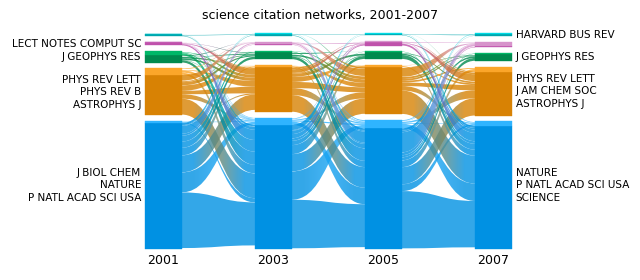

In [40]:
SCIENCE = sorted(DATA.glob("science*.stree"))


def timed(label, fn):
    start = time.perf_counter()
    value = fn()
    seconds = time.perf_counter() - start
    print(f"{label:46} {seconds:5.1f} s")
    return value, seconds


science, t_read = timed("read 4 science networks", lambda: [alluvial.read(p) for p in SCIENCE])
g1, t1 = timed(
    "layout, top modules", lambda: alluvial.layout(science, names=["2001", "2003", "2005", "2007"])
)
g2, t2 = timed("layout, module_level=2", lambda: alluvial.layout(science, module_level=2))
first40 = [m.id for m in g2.networks[0].modules][:40]
g3, t3 = timed(
    "layout, module_level=2 + reverse 40 modules",
    lambda: alluvial.layout(science, module_level=2, module_order={0: first40[::-1]}),
)

print([len(n.modules) for n in g2.networks], "visible modules at level 2")
order = [m.id for m in sorted(g3.networks[0].modules, key=lambda m: -m.y)][:40]  # bottom to top
assert order == first40[::-1]
assert t3 < t2 + 10  # the 40 moves cost about one extra layout, not 40

fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
alluvial.draw(g1, ax, max_label_lines=3)
ax.set_title("science citation networks, 2001-2007", fontsize="medium")

For large diagrams also consider `flow_threshold` (fewer visible modules make every step cheaper) and
`rasterized=True` for compact PDF/SVG files.

That was every public capability. `help(alluvial.layout)`, `help(alluvial.draw)` and the README have the details
of each keyword.

In [41]:
shutil.rmtree(OUT)  # remove the files this notebook wrote